# NINO34 power spectrum, to validate previously shared unexpected results
* NOTE: I am omitting the "weight by cell area" step in averaging NINO34, because I know it won't make too much difference, but this would need to be fixed if these figures were to be used anywhere official/published
* I know there are other ENSO recipes in progress, I wrote this because I just wanted to check some stuff quickly, and I will not take offence if anybody deletes this notebook from the repository :)

In [1]:
import xarray as xr
import numpy as np
import cf_xarray as cfxr
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client

In [2]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 128.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:45137,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:33569,Total threads: 1
Dashboard: http://127.0.0.1:44905/status,Memory: 8.00 GiB
Nanny: tcp://127.0.0.1:43299,


In [3]:
#This cell must be in all notebooks!
#It allows us to run all the notebooks at once, note that the following cell has a tag "parameters" which allows us to pass in arguments externally using papermill (see mkfigs.sh for details)

#parameters

### USER EDIT start
esm_file='/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json'

dpi=300

# papermill settings. *No need to modify these if running interactively.*
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory
nbname = None                          # notebook name


In [4]:
# Parameters
esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/get_cm3website-gogo/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PD-control/"
nbname = "autocorrelation_and_amplitude.ipynb"


In [5]:
import os  # always: the old parameters cell imported it, and notebooks use os.* (TOA_CRE does)
if not papermill:
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter

import matplotlib as mpl
%matplotlib inline
mpl.rcParams['figure.dpi'] = dpi

mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)


### Open the intake-esm datastore

In [6]:
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

### Grabbing NINO34 from a bunch of sources

In [7]:
def calc_nino34(x, lat_var='TLAT', lon_var='TLONG',ave_dims=('nlon','nlat')):
    return x.where((x[lat_var]<5)&(x[lat_var]>-5)&(x[lon_var]%360>190)&(x[lon_var]%360<240)).mean(ave_dims)

In [8]:
NINO34 = {}

In [9]:
# CM3
tos = datastore.search(variable="thetao", frequency="1mon").to_dask(
    xarray_open_kwargs = dict(
        chunks={"z_l": 1, "yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        decode_timedelta=True
    )
).thetao.isel(z_l=0)

coords = datastore.search(variable=["geolat", "geolon"]).to_dask(
    xarray_open_kwargs = dict(
        use_cftime=True
    )
).compute()
coords = coords.fillna(0.0)

tos = tos.assign_coords(coords)

NINO34['CM3'] = calc_nino34(
    tos,
    lat_var='geolat', lon_var='geolon',
    ave_dims=('xh','yh'),
).compute()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


In [10]:
tos = xr.open_mfdataset(
    '/g/data/rt52/era5/single-levels/monthly-averaged/sst/*/*.nc',
    compat="override",
    data_vars="minimal",
    coords="minimal",
    chunks={'latitude':-1,'longitude':-1,'time':12},
    parallel=True,
)
NINO34['ERA5'] = calc_nino34(tos,
                            lat_var='latitude', lon_var='longitude',
                            ave_dims=('longitude','latitude'),
                           ).sst.load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a2037808f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x149fd53c4440>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x149fd4761c40>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145ab3786300>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145ab82a5190>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x154c84799a60>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14dedbb6cd70>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e145a71be0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14b598df8e30>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14b59823b4d0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [11]:
tos = xr.open_mfdataset(
    '/g/data/fs38/publications/CMIP6/CMIP/CSIRO-ARCCSS/ACCESS-CM2/piControl/r1i1p1f1/Omon/tos/gn/latest/*.nc',
    compat="override",
    data_vars="minimal",
    coords="minimal",
    chunks={'i':-1,'j':-1,'time':12},
    use_cftime=True,
    parallel=True,
)

NINO34['CM2_pi'] = calc_nino34(tos,
                            lat_var='latitude', lon_var='longitude',
                            ave_dims=('i','j'),
                           ).tos.load()

In [12]:
tos = xr.open_mfdataset(
    '/g/data/fs38/publications/CMIP6/CMIP/CSIRO-ARCCSS/ACCESS-CM2/historical/r1i1p1f1/Omon/tos/gn/latest/*.nc',
    compat="override",
    data_vars="minimal",
    coords="minimal",
    chunks={'i':-1,'j':-1,'time':12},
    use_cftime=True,
    parallel=True,
)

NINO34['CM2_hist'] = calc_nino34(tos,
                            lat_var='latitude', lon_var='longitude',
                            ave_dims=('i','j'),
                           ).tos.load()

In [13]:
tos = xr.open_mfdataset(
    '/g/data/lg87/wgh581/cz861/history/ocn/ocean_month-ym_*.nc',
    compat="override",
    data_vars="minimal",
    coords="minimal",
    chunks={'xt_ocean':-1,'yt_ocean':-1,'time':12},
    use_cftime=True,
    parallel=True,
    preprocess = lambda x: x.surface_temp,
    decode_timedelta=False,
)
# We are south of 60N
NINO34['CM2_025'] = calc_nino34(tos,
                            lat_var='yt_ocean', lon_var='xt_ocean',
                            ave_dims=('yt_ocean','xt_ocean'),
                           ).surface_temp.load()

### Okayyy, let's make a plot!

In [14]:
def declim(x): # Strip climatology
    return x.groupby('time.month')-x.groupby('time.month').mean()
def clip(x, n=120): # Throw away first 10 years :)
        return x.isel(time=slice(120,None))
def autocorrelation(x, l=48):
    return np.arange(-l,l+1), np.array([np.corrcoef(x[l:-l-1],x[l+i:-l+i-1])[0,1] for i in range(-l,l+1)])

Saved /g/data/tm70/cyb561/repos/get_cm3website-gogo/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PD-control/mkmd/autocorrelation_and_amplitude_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/get_cm3website-gogo/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PD-control/mkmd/autocorrelation_and_amplitude.md


Lines appended to /g/data/tm70/cyb561/repos/get_cm3website-gogo/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PD-control/mkmd/autocorrelation_and_amplitude.md successfully.


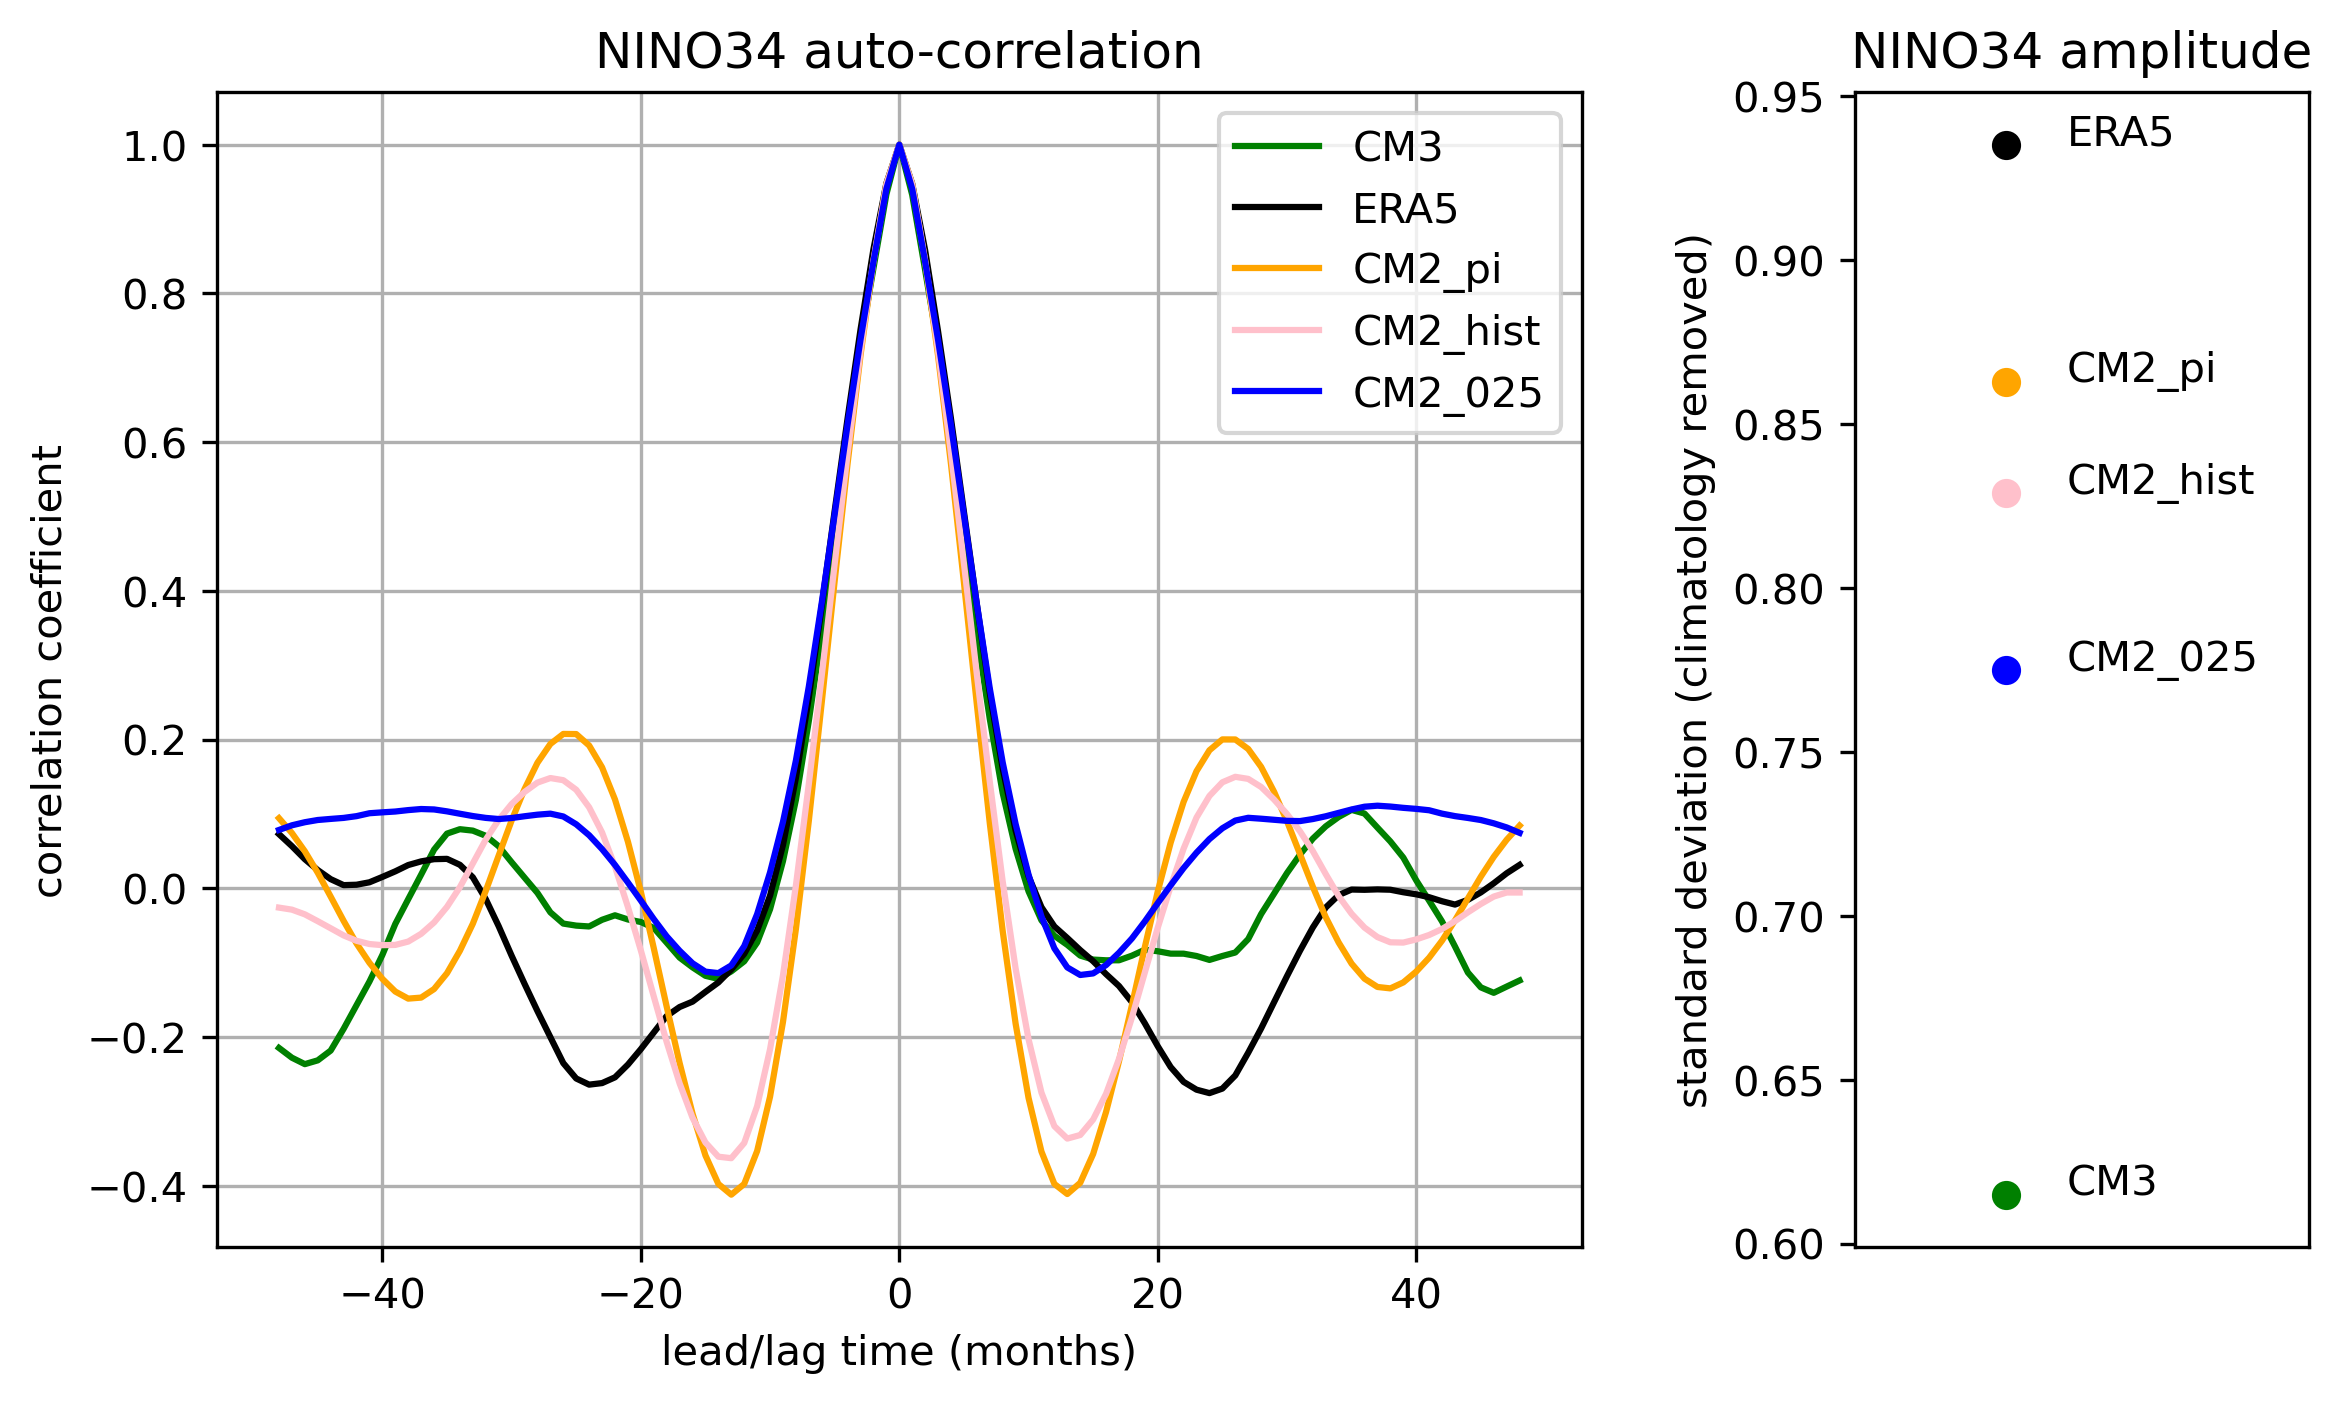

In [15]:
colors = {'ERA5':'k','CM3':'green','CM2_025':'blue','CM2_pi':'orange','CM2_hist':'pink'}

fig, axs = plt.subplots(1,2,figsize=(9,5),width_ratios=(3,1))
plt.sca(axs[0])
for k in NINO34:
    plt.plot(*autocorrelation(declim(clip(NINO34[k]))),label=k,c=colors[k])

plt.legend()

plt.grid()
plt.title('NINO34 auto-correlation')
plt.xlabel('lead/lag time (months)')
plt.ylabel('correlation coefficient')

plt.sca(axs[1])
for k in NINO34:
    plt.scatter(1,np.std(declim(clip(NINO34[k]))),c=colors[k])
    plt.text(1.2,np.std(declim(clip(NINO34[k]))),k)
plt.xlim(0.5,2)

plt.title('NINO34 amplitude')
plt.xticks([])
plt.ylabel('standard deviation (climatology removed)')

plt.subplots_adjust(wspace=0.3)
mkmd.savefig(fig, "NINO34 auto-correlation", "NINO 3.4 auto-correlation.", dpi=dpi)
